In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
import seaborn as sns
import pandas as pd

In [2]:
single_magnitude_data_path = r'17Nov2023\OpenDoor\P01A\A.mat'
single_phase_data_path = r'17Nov2023\OpenDoor\P01A\P.mat'
multi_magnitude_data_path = r'17Nov2023\CloseDoor\P01A\A.mat'
multi_phase_data_path = r'17Nov2023\CloseDoor\P01A\P.mat'

In [3]:
# Loading Data
single_magnitude_data = loadmat(single_magnitude_data_path)["Data_amplitude"]
single_phase_data= loadmat(single_phase_data_path)["Data_phase"]
multi_magnitude_data = loadmat(multi_magnitude_data_path)["Data_amplitude"]
multi_phase_data= loadmat(multi_phase_data_path)["Data_phase"]

# Magnitude

### Average of all data

In [4]:
# Averaging across all data points
single_average_magnitude = np.mean(single_magnitude_data, axis=1)
multi_average_magnitude = np.mean(multi_magnitude_data, axis=1)

In [36]:
single_average_magnitude.shape

(276,)

C:\Users\HP\AppData\Local\Temp\ipykernel_4300\3304745910.py:3: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-whitegrid')


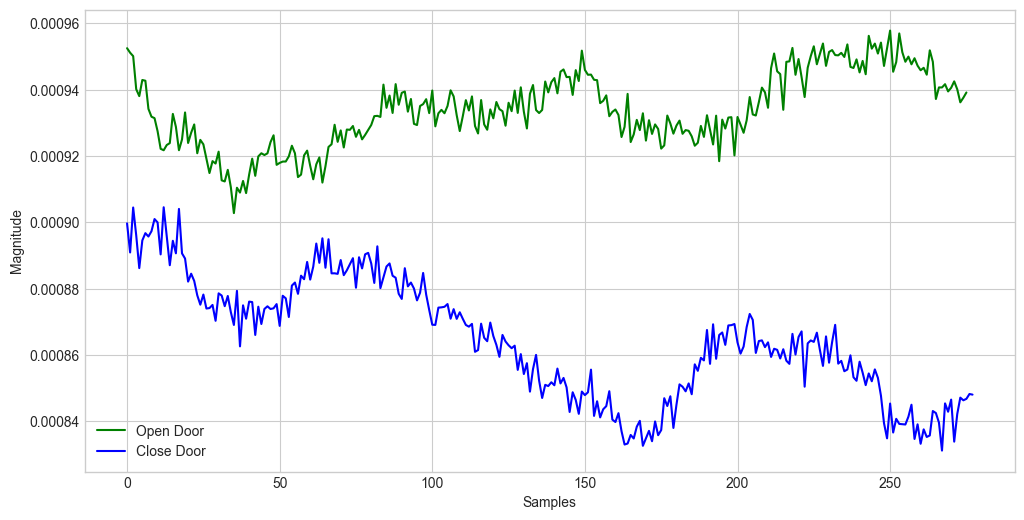

In [9]:

# Plotting the average
plt.figure(figsize=(12, 6))
plt.style.use('seaborn-whitegrid')
plt.plot(single_average_magnitude, label='Open Door', color="green")
plt.plot(multi_average_magnitude, label='Close Door', color="blue")
# plt.plot(average_phase, label='Average Phase')
plt.xlabel('Samples')
plt.ylabel('Magnitude')
plt.legend()
plt.savefig("open_vs_closed.png",bbox_inches='tight')
plt.show()

### moving average filter

In [10]:
def moving_average(data, window_size):
    """ Computes the moving average using a given window size. """
    return np.convolve(data, np.ones(window_size)/window_size, mode='valid')

In [15]:
# Choose a window size
window_size = 200  # Adjust this based on your data

# Apply the moving average filter
single_smoothed_magnitude = moving_average(single_average_magnitude, window_size)
multi_smoothed_magnitude = moving_average(multi_average_magnitude, window_size)

C:\Users\HP\AppData\Local\Temp\ipykernel_4300\2113878938.py:2: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-whitegrid')


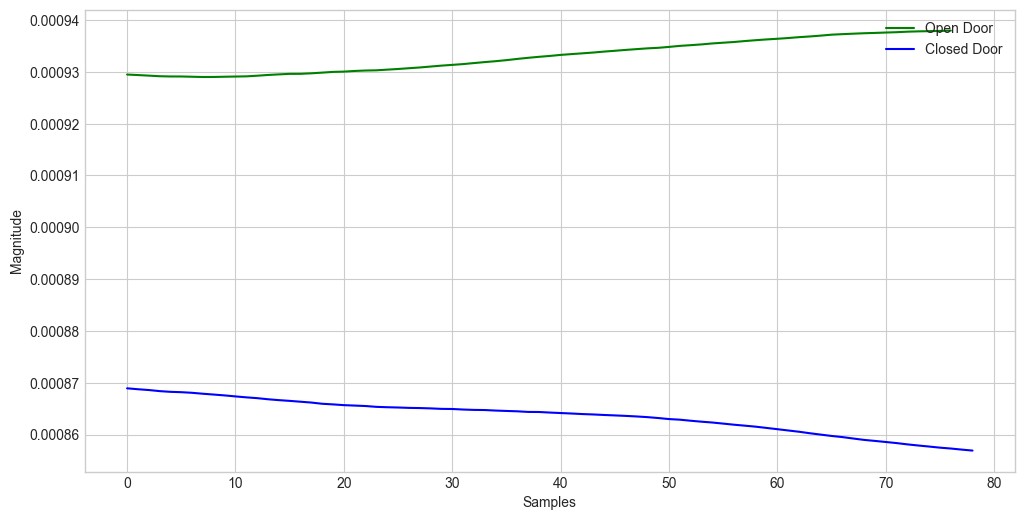

In [16]:
plt.figure(figsize=(12, 6))
plt.style.use('seaborn-whitegrid')
plt.plot(single_smoothed_magnitude, label='Open Door',color="green")
plt.plot(multi_smoothed_magnitude, label='Closed Door', color="blue")
# plt.plot(smoothed_phase, label='Smoothed Average Phase')
plt.xlabel('Samples')
plt.ylabel('Magnitude')
# plt.title('Smoothed Average Magnitude and Phase Over Time')
plt.savefig("open_vs_closed_average.png",bbox_inches='tight')
plt.legend(loc='upper right')
plt.show()

### butterworth filter

In [17]:
from scipy.signal import butter, filtfilt

def butter_lowpass_filter(data, cutoff, fs, order):
    nyquist = 0.5 * fs
    normal_cutoff = cutoff / nyquist
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    y = filtfilt(b, a, data)
    return y

In [23]:
# Filter requirements
order = 10
fs = 25.15  # sample rate, Hz (you mentioned around 25 samples per second)
cutoff = 0.8  # desired cutoff frequency of the filter, Hz

# Apply the filter
single_filtered_magnitude = butter_lowpass_filter(single_average_magnitude, cutoff, fs, order)
multi_filtered_magnitude = butter_lowpass_filter(multi_average_magnitude, cutoff, fs, order)

C:\Users\HP\AppData\Local\Temp\ipykernel_4300\3336595883.py:2: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-whitegrid')


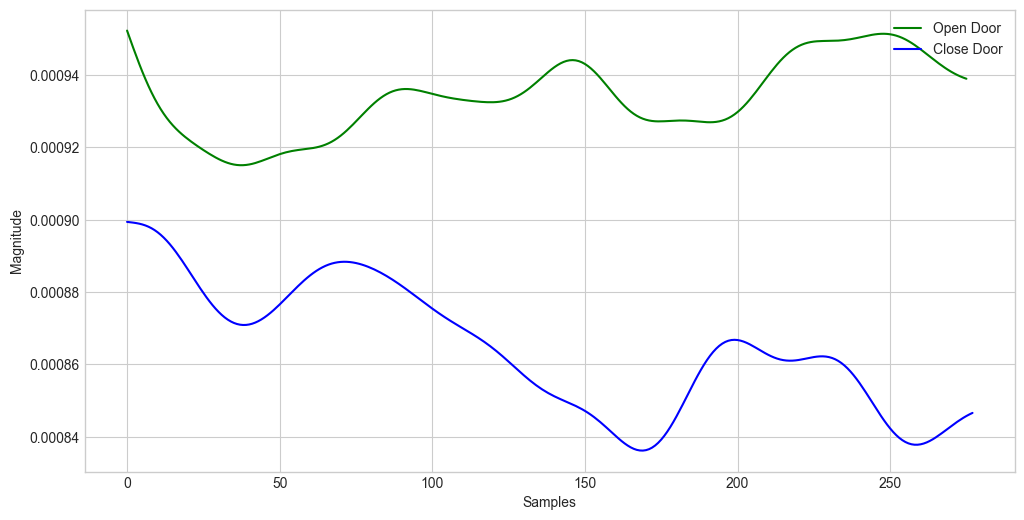

In [26]:
plt.figure(figsize=(12, 6))
plt.style.use('seaborn-whitegrid')
plt.plot(single_filtered_magnitude, label='Open Door', color="green")
plt.plot(multi_filtered_magnitude, label='Close Door', color="blue")
plt.xlabel('Samples')
plt.ylabel('Magnitude')
plt.legend(loc='upper right')
plt.savefig("open_vs_closed_butterworth.png",bbox_inches='tight')
plt.show()

# Phase

### Average of all data

C:\Users\HP\AppData\Local\Temp\ipykernel_4300\859891284.py:7: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-whitegrid')


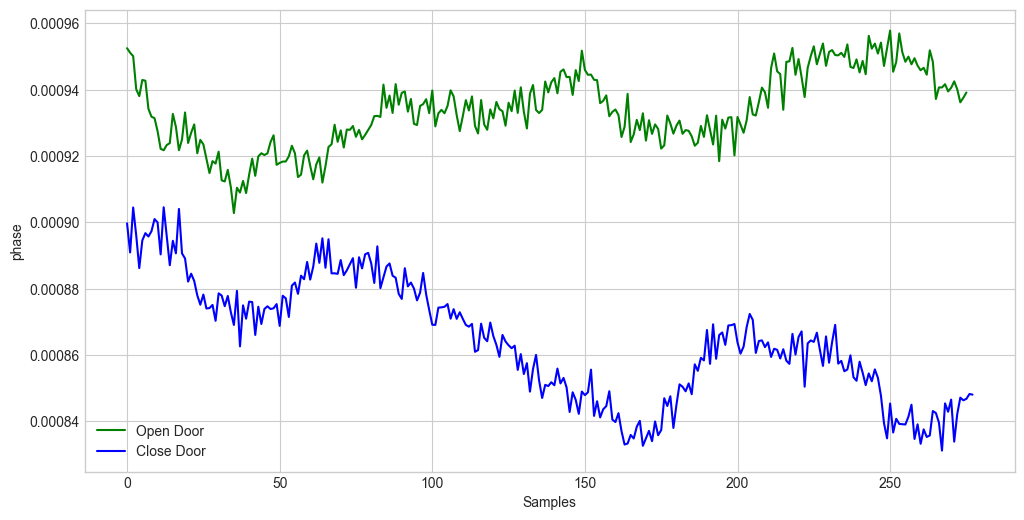

In [27]:
# Averaging across all data points
single_average_phase = np.mean(single_phase_data, axis=1)
multi_average_phase = np.mean(multi_phase_data, axis=1)

# Plotting the average
plt.figure(figsize=(12, 6))
plt.style.use('seaborn-whitegrid')
plt.plot(single_average_magnitude, label='Open Door', color="green")
plt.plot(multi_average_magnitude, label='Close Door', color="blue")
plt.xlabel('Samples')
plt.ylabel('phase')
plt.legend()
plt.savefig("open_vs_closed_Phase.png",bbox_inches='tight')
plt.show()

### moving average filter

In [33]:
# Choose a window size
window_size = 200  # Adjust this based on your data

# Apply the moving average filter
single_smoothed_phase = moving_average(single_average_phase, window_size)
multi_smoothed_phase = moving_average(multi_average_phase, window_size)

C:\Users\HP\AppData\Local\Temp\ipykernel_4300\2814777262.py:2: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-whitegrid')


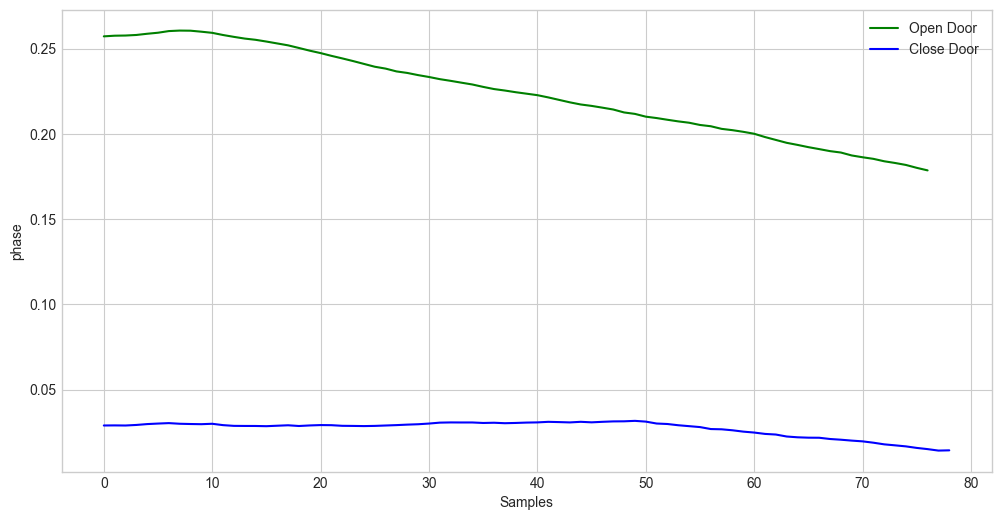

In [34]:
plt.figure(figsize=(12, 6))
plt.style.use('seaborn-whitegrid')
plt.plot(single_smoothed_phase, label='Open Door', color="green")
plt.plot(multi_smoothed_phase, label='Close Door', color="blue")
# plt.plot(smoothed_phase, label='Smoothed Average Phase')
plt.xlabel('Samples')
plt.ylabel('phase')
# plt.title('Smoothed Average phase and Phase Over Time')
plt.savefig("Open_vs_close_average.png",bbox_inches='tight')
plt.legend(loc='upper right')
plt.show()

**Occupancy State**

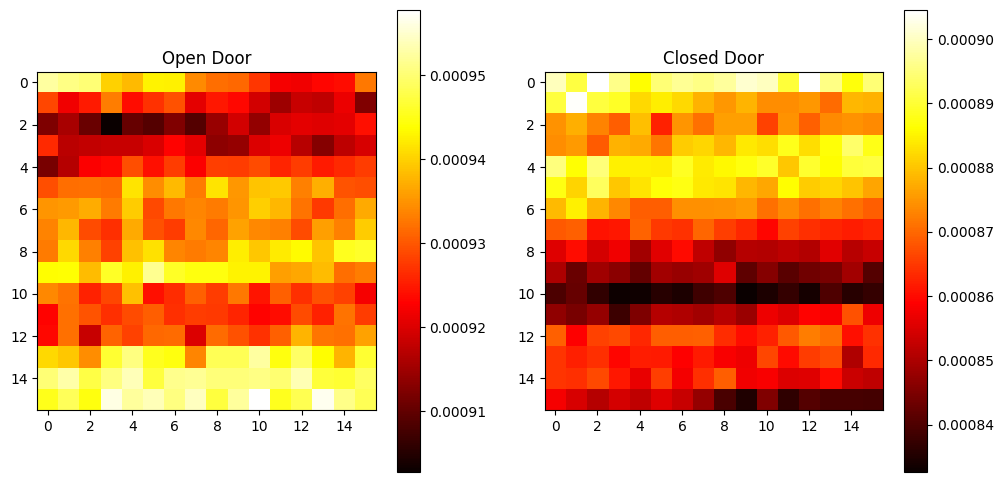

In [16]:
# Reshape the data into a square matrix
size = int(np.sqrt(len(single_average_magnitude)))
single_average_magnitude_2d = single_average_magnitude[:size**2].reshape(size, size)
multi_average_magnitude_2d = multi_average_magnitude[:size**2].reshape(size, size)

# Plot the heatmaps
plt.figure(figsize=(12, 6))

# Heatmap for single_average_magnitude
plt.subplot(1, 2, 1)
plt.title('Open Door')
plt.imshow(single_average_magnitude_2d, cmap='hot', interpolation='nearest')
plt.colorbar()

# Heatmap for multi_average_magnitude
plt.subplot(1, 2, 2)
plt.title('Closed Door')
plt.imshow(multi_average_magnitude_2d, cmap='hot', interpolation='nearest')
plt.colorbar()

plt.savefig("Open_vs_close_heatmap.png",bbox_inches='tight')

plt.show()

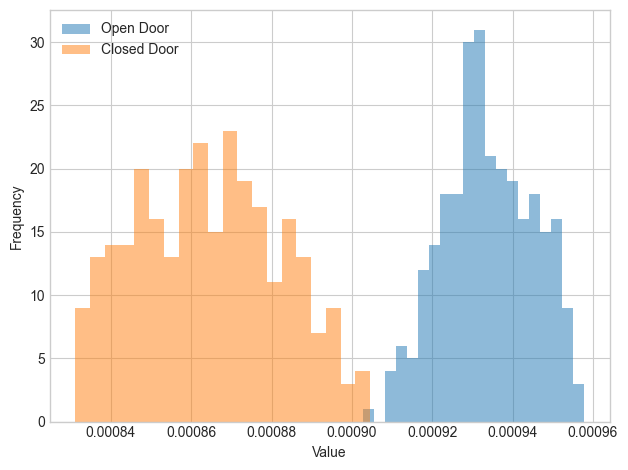

In [36]:
plt.hist(single_average_magnitude, bins=20, alpha=0.5, label='Open Door')
plt.hist(multi_average_magnitude, bins=20, alpha=0.5, label='Closed Door')

plt.xlabel('Value')
plt.ylabel('Frequency')
plt.legend()

plt.tight_layout()
plt.show()

**BeamForming and clutter suppresion**

In [30]:
from scipy.signal import butter, filtfilt

def beamform(signal, num_elements, steering_angle, wavelength):
    """
    Simple delay-and-sum beamformer for a uniform linear array.

    :param signal: Input signal (amplitude and phase).
    :param num_elements: Number of elements in the array.
    :param steering_angle: Desired steering angle in degrees.
    :param wavelength: Wavelength of the radar signal.
    :return: Beamformed signal.
    """
    d = wavelength / 2  # Element spacing (half-wavelength)
    theta = np.radians(steering_angle)  # Convert angle to radians

    # Steering vector
    steering_vector = np.exp(-1j * 2 * np.pi * d / wavelength * np.arange(num_elements) * np.sin(theta))

    # Applying the steering vector to the signal (delay-and-sum)
    beamformed_signal = np.sum(signal * steering_vector[:, None], axis=0)
    return beamformed_signal

def clutter_suppression(signal, cutoff_frequency, sampling_frequency):
    """
    Apply a high-pass filter to suppress clutter.

    :param signal: Input signal.
    :param cutoff_frequency: Cutoff frequency of the high-pass filter.
    :param sampling_frequency: Sampling frequency of the signal.
    :return: Signal after clutter suppression.
    """
    # Design a Butterworth high-pass filter
    b, a = butter(N=4, Wn=cutoff_frequency / (0.5 * sampling_frequency), btype='high')
    filtered_signal = filtfilt(b, a, signal)
    return filtered_signal



In [32]:
#(you will need to adjust these)
NUM_ELEMENTS = 10  # Number of elements in the array
STEERING_ANGLE = 30  # Steering angle in degrees
WAVELENGTH = 0.03  # Wavelength of the radar signal (in meters)
CUTOFF_FREQUENCY = 1  # Cutoff frequency for clutter suppression (in Hz)
SAMPLING_FREQUENCY = 10.0  # Sampling frequency of the radar signal (in Hz)

C:\Users\HP\AppData\Local\Temp\ipykernel_7244\4111483256.py:7: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-whitegrid')
C:\Users\HP\AppData\Roaming\Python\Python39\site-packages\matplotlib\cbook\__init__.py:1335: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


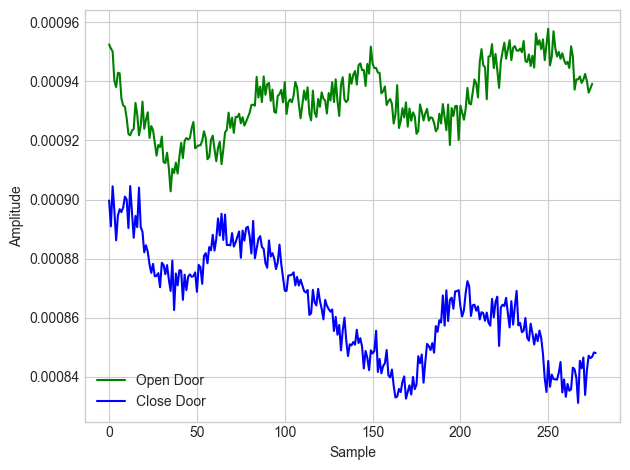

In [33]:
# Beamforming
beamformed_signal_single = beamform(single_average_magnitude, NUM_ELEMENTS, STEERING_ANGLE, WAVELENGTH)
beamformed_signal_multi = beamform(multi_average_magnitude, NUM_ELEMENTS, STEERING_ANGLE, WAVELENGTH)

# Plotting

plt.style.use('seaborn-whitegrid')
plt.plot(beamformed_signal_single, label='Open Door', color="green")
plt.plot(beamformed_signal_multi, label='Close Door', color="blue")

plt.xlabel('Sample')
plt.ylabel('Amplitude')

plt.legend()

# plt.savefig("Open_vs_close_heatmap.png",bbox_inches='tight')

plt.tight_layout()
plt.show()


C:\Users\HP\AppData\Local\Temp\ipykernel_7244\3030343861.py:6: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-whitegrid')
C:\Users\HP\AppData\Roaming\Python\Python39\site-packages\matplotlib\cbook\__init__.py:1335: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


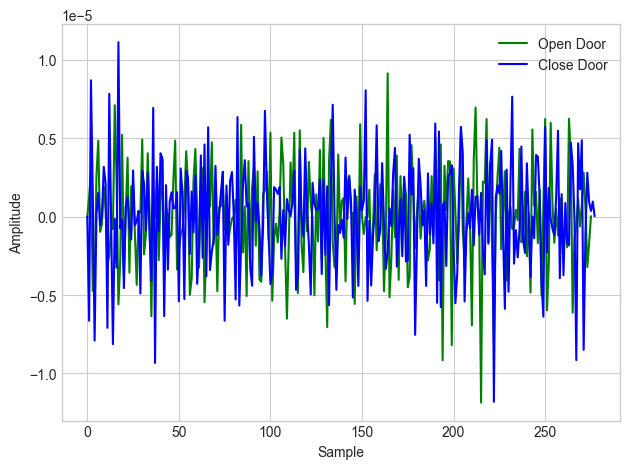

In [34]:
# Clutter Suppression
suppressed_signal_single = clutter_suppression(beamformed_signal_single, CUTOFF_FREQUENCY, SAMPLING_FREQUENCY)
suppressed_signal_multi = clutter_suppression(beamformed_signal_multi, CUTOFF_FREQUENCY, SAMPLING_FREQUENCY)


plt.style.use('seaborn-whitegrid')
plt.plot(suppressed_signal_single, label='Open Door', color="green")
plt.plot(suppressed_signal_multi, label='Close Door', color="blue")

plt.xlabel('Sample')
plt.ylabel('Amplitude')

plt.legend()

# plt.savefig("Open_vs_close_heatmap.png",bbox_inches='tight')

plt.tight_layout()
plt.show()




**Wavellet Transform**

In [6]:
import pywt

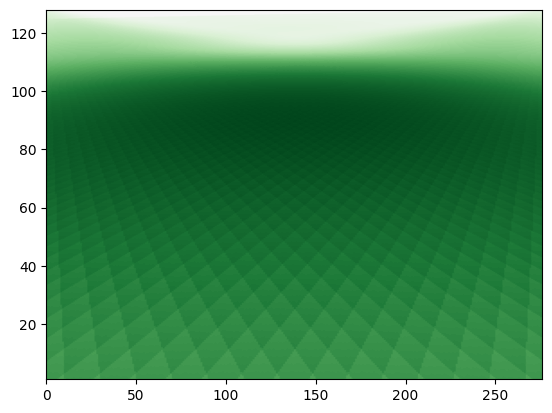

In [8]:
# Choosing a wavelet
wavelet = 'cmor'

# Define scales
scales = np.arange(1, 1280)

# Performing the CWT
coefficients, frequencies = pywt.cwt(single_average_magnitude, scales, wavelet)

# Plotting the wavelet transform
plt.imshow(np.abs(coefficients), extent=[0, 276, 1, 128], cmap='PRGn', aspect='auto',
           vmax=abs(coefficients).max(), vmin=-abs(coefficients).max())
plt.show()

D:\Softwares\Installed Softwares\Anaconda\lib\site-packages\pywt\_cwt.py:117: FutureWarning: Wavelets from the family cmor, without parameters specified in the name are deprecated. The name should takethe form cmorB-C where B and C are floats representing the bandwidth frequency and center frequency, respectively (example: cmor1.5-1.0).
  wavelet = DiscreteContinuousWavelet(wavelet)


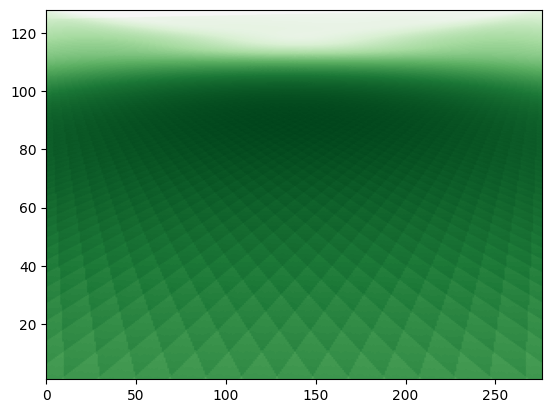

In [7]:
# Choosing a wavelet
wavelet = 'cmor'

# Define scales
scales = np.arange(1, 1280)

# Performing the CWT
coefficients, frequencies = pywt.cwt(multi_average_magnitude, scales, wavelet)

# Plotting the wavelet transform
plt.imshow(np.abs(coefficients), extent=[0, 276, 1, 128], cmap='PRGn', aspect='auto',
           vmax=abs(coefficients).max(), vmin=-abs(coefficients).max())
plt.show()

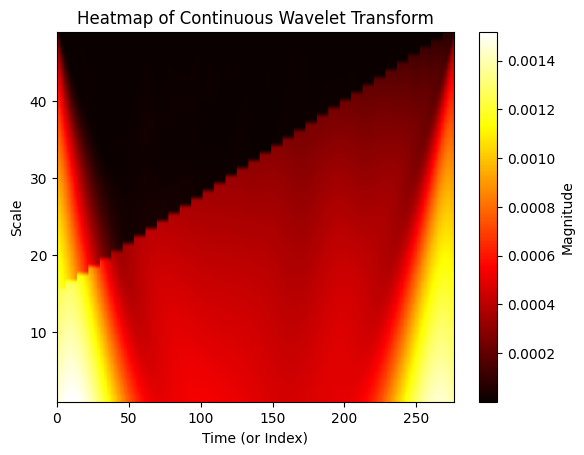

In [13]:
# Choosing a wavelet
wavelet = 'cmor'

# Define scales - adjust this based on the frequency content you are interested in
scales = np.arange(1, 50)  # Adjust this range as needed

# Performing the CWT
coefficients, frequencies = pywt.cwt(multi_average_magnitude, scales, wavelet)

# Plotting the heatmap
plt.imshow(np.abs(coefficients), extent=[0, len(single_average_magnitude), min(scales), max(scales)], 
           cmap='hot', aspect='auto')

# Adding a color bar to understand the scale of values
plt.colorbar(label='Magnitude')

# Labeling Axes
plt.xlabel('Time (or Index)')
plt.ylabel('Scale')
plt.title('Heatmap of Continuous Wavelet Transform')

plt.show()
